# Chapter 1 — TD-PINNs: Time-Integrator Comparison (fixed epochs)

**Case:** 1-D viscous Burgers, sawtooth analytic solution (Hopf–Cole) on $[0, 2\pi]$, spatial operator
$S(u) \equiv u\,u_x - \nu\,u_{xx}$ (so the PDE is $u_t + S(u) = 0$).

**Goal:** keep the **native `PINTrainer`** (TD-PINNs, MLP, fixed uniform collocation) and vary *only* the
time integrator. The integrator is **not** a trainer setting — it lives entirely in the residual
function (the loss function). The trainer hands the residual a `u_prev` that keeps its graph w.r.t. $x$,
so a residual can differentiate the frozen previous step when it needs to:

| integrator | residual $R$ (we minimise $\langle R^2\rangle$) | $S$ from |
|---|---|---|
| **Explicit Euler** | $\dfrac{u-u^{t-1}}{\Delta t} + S(u^{t-1})$ | frozen $t{-}1$ |
| **Implicit Euler** | $\dfrac{u-u^{t-1}}{\Delta t} + S(u)$ | current $t$ (AD) |
| **Crank–Nicolson** | $\dfrac{u-u^{t-1}}{\Delta t} + \tfrac12\big[S(u) + S(u^{t-1})\big]$ | half / half |

The Crank–Nicolson residual is the requested scheme:
$\frac{u^{t}-u^{t-1}}{\Delta t} = \tfrac12[(\nu u_{xx}^{t-1} - u^{t-1}u_x^{t-1}) + (\nu u_{xx}^{t} - u^{t}u_x^{t})]$.

**What is different in this variant:** the number of **epochs is fixed** (no early stopping —
`TOLERANCE = 0`, so every step runs the full budget). Each integrator is summarised as a single point
whose **horizontal axis is the training loss reached** at that fixed budget, and whose vertical axis is
the error vs the analytical solution. Lower-left = lower loss *and* lower error for the same number of
epochs.

In [1]:
import sys, os, time

ROOT = '/home/df.gomezb/Tesis'
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pinns_framework import (
    PINArchitecture, PINSpatialDimension, PINLossFunction, PINTrainer,
    compute_metrics, collocation_uniform,
)

torch.manual_seed(0)
np.random.seed(0)
print('torch:', torch.__version__)

torch: 2.12.1+cu130


## 1. Problem setup — sawtooth analytic solution

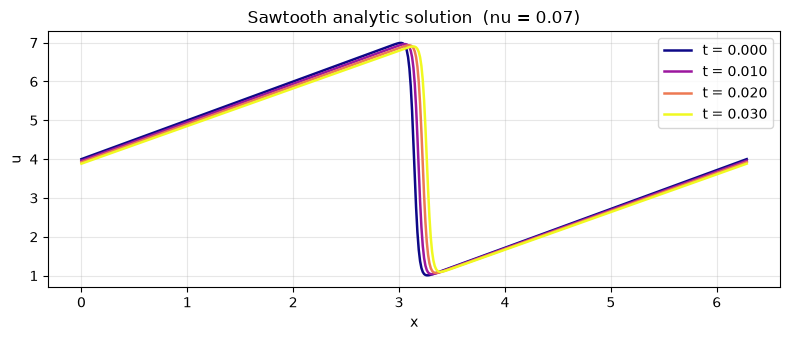

In [2]:
NU     = 0.07
X0, XF = 0.0, 2 * np.pi

def toothsaw(t, x):
    """Hopf-Cole analytic solution for viscous Burgers on [0, 2pi]."""
    x  = np.asarray(x, dtype=float)
    nu = NU
    c  = 4 * nu * (t + 1)
    a  = (-4*t + x)**2           / c
    b  = (-4*t + x - 2*np.pi)**2 / c
    num = ((-8*t + 2*x)            * np.exp(-a)
         + (-8*t + 2*x - 4*np.pi) * np.exp(-b)) / c
    den = np.exp(-b) + np.exp(-a)
    return 2 * nu * num / den + 4

x_plot = np.linspace(X0, XF, 500)
fig, ax = plt.subplots(figsize=(8, 3.5))
cmap = plt.cm.plasma
for i, t in enumerate([0.0, 0.01, 0.02, 0.03]):
    ax.plot(x_plot, toothsaw(t, x_plot), color=cmap(i / 3), lw=1.8, label=f't = {t:.3f}')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title('Sawtooth analytic solution  (nu = 0.07)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Experiment configuration

In [ ]:
ARCH        = 'MLP'
PARAMS_ARCH = {'layers': (1, 32, 32, 32, 1), 'activation': 'tanh'}

DT     = 0.005
T_END  = 0.025
NT     = round(T_END / DT)

EPOCHS     = 50000          # FIXED epoch budget per step (spent in full)
TOLERANCE  = 0.0           # no early stopping -> every step runs EPOCHS epochs
LR         = 1e-2
IC_WEIGHT  = 15.0/( (15**2+5**2+1**2)**(1/2) )
BC_WEIGHT  = 5.0/( (15**2+5**2+1**2)**(1/2) )
PDE_WEIGHT = 1.0/( (15**2+5**2+1**2)**(1/2) )
N_COLLOC   = 500
N_EVAL     = 1000

times = [k * DT for k in range(NT + 1)]
print(f'{NT} PDE steps of dt={DT}  ->  T={T_END}   |   fixed {EPOCHS} epochs/step')

## 3. IC / BC and the three integrator residuals (the lf)

Each residual receives `u` (current net), `u_prev` (frozen previous net, **graph kept** so we can take
its $x$-derivatives), `x`, `dt`, and `nu`. The spatial operator $S(w) = w\,w_x - \nu\,w_{xx}$ is computed
by autograd; frozen-step terms are detached so no gradient reaches the previous network.

In [4]:
x_ic_np = np.linspace(X0, XF, 201)
u_ic_np = toothsaw(0, x_ic_np)
x_ic = torch.tensor(x_ic_np, dtype=torch.float32).unsqueeze(1)
u_ic = torch.tensor(u_ic_np, dtype=torch.float32).unsqueeze(1)

u_bc_val = float(toothsaw(0, X0))
x_bc = torch.tensor([[X0], [XF]], dtype=torch.float32)
u_bc = torch.full((2, 1), u_bc_val, dtype=torch.float32)
print(f'IC range: [{u_ic.min():.3f}, {u_ic.max():.3f}]   BC value: {u_bc_val:.4f}')

x_dim = PINSpatialDimension('x', domain=(X0, XF), n_colloc=N_COLLOC)

def make_residual(scheme):
    """Return a TD-PINN residual_fn implementing the chosen time integrator.

    The integrator is encoded here (the loss function), NOT in the trainer.
    """
    def residual(u, u_prev, x, dt, nu):
        def S(w):                                   # spatial operator w*w_x - nu*w_xx
            w_x  = torch.autograd.grad(w.sum(),   x, create_graph=True)[0]
            w_xx = torch.autograd.grad(w_x.sum(), x, create_graph=True)[0]
            return w * w_x - nu * w_xx
        u_prev_val = u_prev.detach()
        if scheme == 'EE':                          # Explicit Euler
            return (u - u_prev_val) / dt + S(u_prev).detach()
        if scheme == 'IE':                          # Implicit (Backward) Euler
            return (u - u_prev_val) / dt + S(u)
        if scheme == 'CN':                          # Crank-Nicolson
            return (u - u_prev_val) / dt + 0.5 * (S(u) + S(u_prev).detach())
        raise ValueError(scheme)
    return residual

INTEGRATORS = {
    'Explicit Euler' : 'EE',
    'Implicit Euler' : 'IE',
    'Crank-Nicolson' : 'CN',
}

def exact_fn(t, x_pts):
    u = toothsaw(t, x_pts.detach().cpu().numpy().ravel())
    return torch.tensor(u, dtype=torch.float32, device=x_pts.device).unsqueeze(1)

IC range: [1.006, 6.994]   BC value: 4.0000


## 4. Run every integrator with the native `PINTrainer`

Same architecture, seed, collocation, and **fixed** epoch budget for all three — only the `loss_fn`
(hence the integrator) changes. We record the **loss each step ends at** (`step_history`'s `final_loss`)
and the error norms $L_1$, $L_2$, $L_\infty$ vs the analytical solution.

In [ ]:
records = {}

for name, code in INTEGRATORS.items():
    torch.manual_seed(0); np.random.seed(0)
    net = PINArchitecture(ARCH, PARAMS_ARCH)
    loss_fn = PINLossFunction([x_dim], make_residual(code))
    trainer = PINTrainer(
        net=net, scheme='TD-PINNS', loss_fn=loss_fn, spatial_dims=[x_dim],
        epochs=EPOCHS, dt=DT, lr=LR, tolerance=TOLERANCE,
        ic_weight=IC_WEIGHT, bc_weight=BC_WEIGHT, pde_weight=PDE_WEIGHT,
        collocation_fn=collocation_uniform, verbose=True, log_every=1000
    )
    t0 = time.perf_counter()
    nets = trainer.fit(x_ic=x_ic, u_ic=u_ic, x_bc=x_bc, u_bc=u_bc, T=T_END, nu=NU)
    wall = time.perf_counter() - t0

    pde_steps    = trainer.step_history[1:]                      # skip the IC fit
    final_losses = [h['final_loss'] for h in pde_steps]          # loss reached per step (fixed epochs)
    df = compute_metrics(nets, times, [x_dim], n_eval=N_EVAL,
                         exact_fn=exact_fn, device=trainer.device)

    # compute_metrics gives L2 / Linf — add L1 (mean-abs) per level
    xg = torch.linspace(X0, XF, N_EVAL).unsqueeze(1).to(trainer.device)
    l1 = []
    for t, net_t in zip(times, nets):
        net_t.eval()
        with torch.no_grad():
            up = net_t(xg)
            if up.dim() == 1:
                up = up.unsqueeze(1)
        l1.append(float((up - exact_fn(t, xg)).abs().mean()))
    df['L1'] = l1

    records[name] = {
        'mean_loss'        : float(np.mean(final_losses)),       # <- new horizontal axis
        'final_loss_series': final_losses,
        'mean_L1'          : float(df['L1'].mean()),
        'mean_L2'          : float(df['L2'].mean()),
        'mean_Linf'        : float(df['Linf'].mean()),
        'final_Linf'       : float(df['Linf'].iloc[-1]),
        'wall_s'           : wall,
        'linf_series'      : df['Linf'],
        'nets'             : nets,
        'device'           : trainer.device,
    }
    print(f'{name:16s} | mean loss {np.mean(final_losses):.4e} '
          f'| mean Linf {df["Linf"].mean():.4e} | wall {wall:5.1f}s')

## 5. (loss, $L_\infty$) — one point per integrator

Horizontal axis: **mean training loss reached** after the fixed `EPOCHS` (averaged over the PDE steps).
Vertical axis: mean $L_\infty$ error vs exact. **Lower-left is better** (lower loss *and* lower error for
the same number of epochs). Saved to `figs/` as a PDF.

In [ ]:
os.makedirs('figs', exist_ok=True)
colors  = {'Explicit Euler': 'tab:red', 'Implicit Euler': 'tab:blue', 'Crank-Nicolson': 'tab:green'}
markers = {'Explicit Euler': 'o',       'Implicit Euler': 's',        'Crank-Nicolson': '^'}

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for name, r in records.items():
    c = colors[name]
    ax.scatter(r['mean_loss'], r['mean_Linf'], s=180, marker=markers[name],
               color=c, edgecolors='k', linewidths=0.8, zorder=3, label=name)
    ax.annotate(name, (r['mean_loss'], r['mean_Linf']),
                textcoords='offset points', xytext=(8, 5), fontsize=9, color=c)

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(f'mean training loss after {EPOCHS} epochs  (PDE steps)')
ax.set_ylabel(r'mean $L_\infty$ error vs exact')
ax.set_title('TD-PINNs sawtooth — time integrators at fixed epochs\n(lower-left = lower loss & lower error)')
ax.grid(True, which='both', alpha=0.3); ax.legend()
plt.tight_layout()
fig.savefig('figs/time_integrators_loss_vs_linf.pdf', bbox_inches='tight')
print('saved -> figs/time_integrators_loss_vs_linf.pdf')
plt.show()

## 6. Summary table and per-level $L_\infty$

In [ ]:
summary = pd.DataFrame([
    {'integrator': n, 'mean_loss': r['mean_loss'],
     'mean_L1': r['mean_L1'], 'mean_L2': r['mean_L2'], 'mean_Linf': r['mean_Linf'],
     'final_Linf': r['final_Linf'], 'wall_s': r['wall_s']}
    for n, r in records.items()
]).set_index('integrator').sort_values('mean_loss')
pd.set_option('display.float_format', '{:.4e}'.format)
print('=== Time-integrator summary at fixed epochs (sorted by mean loss) ===')
print(summary.to_string())
print(f'\nLowest loss: {summary.index[0]}   |   lowest mean Linf: {summary["mean_Linf"].idxmin()}')

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
for name, r in records.items():
    ax.semilogy(times, r['linf_series'].values, '-o', ms=4, lw=1.5, color=colors[name], label=name)
ax.set_xlabel('t'); ax.set_ylabel(r'$L_\infty$ error')
ax.set_title('Final Linf error per time level')
ax.legend(fontsize=9); ax.grid(True, which='both', alpha=0.3)

ax = axes[1]
x_eval = torch.linspace(X0, XF, N_EVAL).unsqueeze(1)
xev_np = x_eval.numpy().ravel()
ax.plot(xev_np, toothsaw(T_END, xev_np), 'k-', lw=2.2, label='exact')
for name, r in records.items():
    net = r['nets'][-1].eval()
    with torch.no_grad():
        u = net(x_eval.to(r['device'])).cpu().numpy().ravel()
    ax.plot(xev_np, u, lw=1.3, color=colors[name], alpha=0.85, label=name)
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title(f'Solution at t = {T_END:.3f}')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Notes

- **Fixed epochs**: `TOLERANCE = 0` means every step trains the full `EPOCHS`, so the horizontal axis is
  no longer "epochs to converge" (constant now) but the **loss the optimiser reached** at that budget.
- The point plot then reads as: for the same compute, which integrator drives the residual loss lowest,
  and does lower loss translate into lower $L_\infty$ error? A method sitting lower-left wins on both.
- The integrator still lives entirely in the `loss_fn` (the residual); the trainer is unchanged.
- Explicit Euler carries the explicit scheme's CFL sensitivity; Crank–Nicolson is $O(\Delta t^2)$ and
  usually most accurate at the same `DT`.